# 05 · Interpretación, sesgo y modelo final (Producto 2)
1. ¿Qué variables pesan más en la predicción?
2. ¿El modelo se equivoca más con algún grupo (sexo, zona, lengua, edad)?
3. Guardamos el modelo final para la demo.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Datos: EPEN 2025 (INEI), departamento de Puno. El archivo está en data/ del repositorio.
NOMBRE = "21_Puno_EPEN_Anual_2025.csv"
RUTA = next((r for r in [f"../data/{NOMBRE}", f"data/{NOMBRE}", NOMBRE] if Path(r).exists()),
            "https://raw.githubusercontent.com/[USUARIO]/[REPOSITORIO]/main/data/" + NOMBRE)  # <- reemplazar

NUMERICAS = ["edad", "horas_semana", "ingreso_log", "n_limitaciones", "anios_estudio"]
CATEGORICAS = ["sexo", "area", "educacion", "lengua", "etnia", "ocupacion", "rama", "quiere_mas_horas"]

EDUC = {1: "Sin nivel/inicial", 2: "Sin nivel/inicial", 3: "Primaria incompleta", 4: "Primaria completa",
        5: "Secundaria incompleta", 6: "Secundaria completa", 7: "Sin nivel/inicial",
        8: "Superior no univ. incompleta", 9: "Superior no univ. completa",
        10: "Superior univ. incompleta", 11: "Superior univ. completa", 12: "Posgrado"}
ANIOS = {1: 0, 2: 0, 3: 3, 4: 6, 5: 8, 6: 11, 7: 0, 8: 12, 9: 14, 10: 13, 11: 16, 12: 18}  # años de estudio aprox.
OCUP = {0: "Fuerzas armadas", 1: "Directivos", 2: "Profesionales", 3: "Técnicos", 4: "Empleados de oficina",
        5: "Servicios y vendedores", 6: "Agricultores y pecuarios", 7: "Oficiales y artesanos",
        8: "Operadores de maquinaria", 9: "Ocupaciones elementales"}      # CIUO-08, gran grupo

def rama_ciiu(codigo):
    """Agrupa la división CIIU (4 dígitos, sin el cero inicial) en grandes ramas."""
    d = int(codigo) // 100
    if d <= 3:  return "Agricultura y pesca"
    if d <= 9:  return "Minería"
    if d <= 33: return "Manufactura"
    if d <= 39: return "Electricidad y agua"
    if d <= 43: return "Construcción"
    if d <= 47: return "Comercio"
    if d <= 53: return "Transporte"
    if d <= 56: return "Alojamiento y comidas"
    if d <= 82: return "Servicios a empresas"
    if d == 84: return "Administración pública"
    if d == 85: return "Educación"
    if d <= 88: return "Salud"
    return "Otros servicios y hogares"

def cargar_datos():
    raw = pd.read_csv(RUTA)
    # Población de estudio: personas OCUPADAS (OCUP300 = 1) con el indicador de informalidad del INEI
    d = raw[(raw["OCUP300"] == 1) & raw["Informal_P"].notna()].copy()
    out = pd.DataFrame({
        "edad": d["C208"], "horas_semana": d["whoraT"], "ingreso_log": np.log1p(d["INGTOTP"]),
        "n_limitaciones": (d[[f"C375_{i}" for i in range(1, 7)]] == 1).sum(axis=1),
        "anios_estudio": d["C366"].map(ANIOS),
        "sexo": d["C207"].map({1: "Hombre", 2: "Mujer"}),
        "area": d["AREA"].map({1: "Urbano", 2: "Rural"}),
        "educacion": d["C366"].map(EDUC),
        "lengua": d["C376"].map({1: "Quechua", 2: "Aimara", 10: "Castellano"}).fillna("Otra"),
        "etnia": d["C377"].map({1: "Quechua", 2: "Aimara", 6: "Blanco", 7: "Mestizo"}).fillna("Otra/No sabe"),
        "ocupacion": (d["C308_COD"] // 1000).map(OCUP),
        "rama": d["C309_COD"].map(rama_ciiu),
        "quiere_mas_horas": d["C333"].map({1: "Sí", 2: "No"}).fillna("No"),
        "informal": (d["Informal_P"] == 1).astype(int),     # 1 = empleo informal, 2 = formal (ver data/README.md)
        "grupo": d["LLAVE_PANEL"].astype(str),               # identifica a la persona (el panel la repite)
        "ingreso": d["INGTOTP"]})
    return out.reset_index(drop=True)

df = cargar_datos()
X, y, grupos = df[NUMERICAS + CATEGORICAS], df["informal"], df["grupo"]
print(df.shape, f"| empleo informal: {y.mean():.1%} | personas distintas: {grupos.nunique()}")

(7836, 16) | empleo informal: 77.8% | personas distintas: 5479


In [2]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Misma división en todos los notebooks: 80 % entrenamiento / 20 % test, sin repartir a una persona entre ambos
idx_tr, idx_te = next(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(X, y, grupos))
X_tr, X_te, y_tr, y_te = X.iloc[idx_tr], X.iloc[idx_te], y.iloc[idx_tr], y.iloc[idx_te]
g_tr = grupos.iloc[idx_tr]
cv = StratifiedGroupKFold(5, shuffle=True, random_state=42)   # validación cruzada por persona

def preprocesador():
    num = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    cat = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, NUMERICAS), ("cat", cat, CATEGORICAS)])

print(f"entrenamiento: {len(X_tr)} filas · test: {len(X_te)} filas · personas compartidas: {len(set(g_tr) & set(grupos.iloc[idx_te]))}")

entrenamiento: 6269 filas · test: 1567 filas · personas compartidas: 0


In [3]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, recall_score

# Hiperparámetros ganadores del notebook 03 (actualizarlos si al repetir la búsqueda cambian)
PARAMS = dict(max_iter=284, learning_rate=0.0148, max_leaf_nodes=33, min_samples_leaf=70,
              l2_regularization=0.0766, max_features=0.7826)
# Modelo final: gradient boosting optimizado (supera a la logística en 24 de 25 folds; ver notebook 03)
final = Pipeline([("prep", preprocesador()),
                  ("modelo", HistGradientBoostingClassifier(class_weight="balanced", random_state=42, **PARAMS))]).fit(X_tr, y_tr)
referencia = Pipeline([("prep", preprocesador()),
                       ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced"))]).fit(X_tr, y_tr)

# Evaluación final en el test (la logística se muestra solo como referencia; no se usó para elegir)
for nombre, m in [("Boosting optimizado (final)", final), ("Regresión logística (referencia)", referencia)]:
    p = m.predict(X_te)
    print(f"{nombre:<34} exactitud balanceada = {balanced_accuracy_score(y_te, p):.3f} · "
          f"ROC-AUC = {roc_auc_score(y_te, m.predict_proba(X_te)[:, 1]):.3f} · "
          f"recall informales = {recall_score(y_te, p):.3f} · recall formales = {recall_score(y_te, p, pos_label=0):.3f}")

Boosting optimizado (final)        exactitud balanceada = 0.888 · ROC-AUC = 0.956 · recall informales = 0.897 · recall formales = 0.879
Regresión logística (referencia)   exactitud balanceada = 0.881 · ROC-AUC = 0.952 · recall informales = 0.881 · recall formales = 0.882


## 1 · Importancia por permutación (en el test)

ingreso_log      0.107
rama             0.058
anios_estudio    0.012
edad             0.008
ocupacion        0.007
horas_semana     0.004
dtype: float64


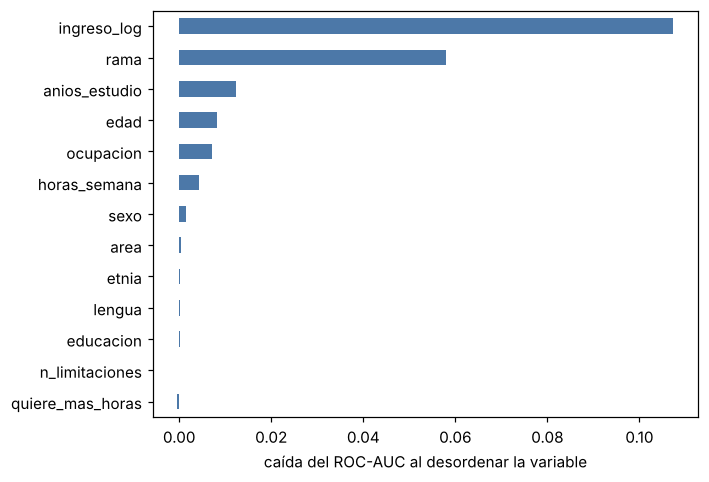

In [4]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(final, X_te, y_te, scoring="roc_auc", n_repeats=10, random_state=42)
imp = pd.Series(perm.importances_mean, index=X_te.columns).sort_values()
imp.plot.barh(color="#4C78A8"); plt.xlabel("caída del ROC-AUC al desordenar la variable"); plt.show()
print(imp.sort_values(ascending=False).round(3).head(6))

**Lectura:** el modelo se apoya sobre todo en el **ingreso mensual** (caída de 0,107 en el ROC-AUC al desordenarlo) y en la **rama de actividad** (0,058). Detrás vienen los años de estudio, la edad, la ocupación y las horas trabajadas, con aportes pequeños. Coincide con el análisis exploratorio: quien trabaja en agricultura, comercio o servicios básicos y gana poco es casi siempre informal. Las variables de sexo, zona, lengua y etnia casi no pesan por sí solas (ver gráfico).

Si **quitamos el ingreso**, el modelo baja de 0,888 a **0,864** de exactitud balanceada (ROC-AUC de 0,956 a 0,943): pierde algo, pero sigue siendo útil, porque la rama, la ocupación y la educación aportan la mayor parte de la señal.

### ¿Y sin el ingreso?
El ingreso es la variable más fuerte, pero puede ser en parte **consecuencia** de la informalidad (quien no tiene contrato suele ganar menos). Comprobamos cuánto cae el desempeño si lo quitamos.

In [5]:
def preprocesador_sin_ingreso():
    num = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    cat = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, [c for c in NUMERICAS if c != "ingreso_log"]), ("cat", cat, CATEGORICAS)])

sin_ingreso = Pipeline([("prep", preprocesador_sin_ingreso()),
                        ("modelo", HistGradientBoostingClassifier(class_weight="balanced", random_state=42, **PARAMS))]).fit(X_tr, y_tr)
p = sin_ingreso.predict(X_te)
print(f"Sin ingreso · exactitud balanceada = {balanced_accuracy_score(y_te, p):.3f} · "
      f"ROC-AUC = {roc_auc_score(y_te, sin_ingreso.predict_proba(X_te)[:, 1]):.3f} · "
      f"recall informales = {recall_score(y_te, p):.3f} · recall formales = {recall_score(y_te, p, pos_label=0):.3f}")

Sin ingreso · exactitud balanceada = 0.864 · ROC-AUC = 0.943 · recall informales = 0.887 · recall formales = 0.841


## 2 · ¿Trata distinto a algún grupo?

In [6]:
pred = final.predict(X_te)
d = X_te.assign(real=y_te.values, pred=pred, edad_tramo=pd.cut(X_te["edad"], [13, 29, 49, 120], labels=["14–29", "30–49", "50 o más"]))
filas = []
for col in ["sexo", "area", "lengua", "edad_tramo"]:
    for g, s in d.groupby(col, observed=True):
        if len(s) < 30: continue
        filas.append({"grupo": f"{col}: {g}", "n": len(s), "n formales": int((s.real == 0).sum()), "% informal real": round(s.real.mean() * 100),
                      "% predicho informal": round(s.pred.mean() * 100),
                      "recall informales": round(recall_score(s.real, s.pred), 2),
                      "recall formales": round(recall_score(s.real, s.pred, pos_label=0), 2),
                      "exactitud balanceada": round(balanced_accuracy_score(s.real, s.pred), 2)})
pd.DataFrame(filas).set_index("grupo")

,n,n formales,% informal real,% predicho informal,recall informales,recall formales,exactitud balanceada
grupo,,,,,,,
sexo: Hombre,771,217,72,65,0.87,0.90,0.88
sexo: Mujer,796,130,84,80,0.92,0.84,0.88
area: Rural,283,8,97,96,0.99,0.88,0.93
area: Urbano,1284,339,74,67,0.87,0.88,0.87
lengua: Aimara,318,46,86,82,0.93,0.87,0.90
lengua: Castellano,676,233,66,58,0.82,0.89,0.86
lengua: Quechua,571,66,88,85,0.94,0.85,0.90
edad_tramo: 14–29,314,31,90,83,0.89,0.74,0.82
edad_tramo: 30–49,654,175,73,67,0.87,0.88,0.88


**Lectura (test, 1 567 trabajadores):**
- **Sexo:** la exactitud balanceada es igual (0,88), pero los errores son distintos. El modelo detecta al 92 % de las mujeres informales y al 87 % de los hombres informales, y **clasifica mal como informales al 16 % de las mujeres formales contra el 10 % de los hombres formales**.
- **Lengua materna:** detecta al 94 % de los informales quechuas, pero solo al **82 % de los informales de lengua castellana** (más se le "escapan"). Desempeño más bajo en castellano (0,86) que en quechua o aimara (0,90).
- **Edad:** los trabajadores formales de **14 a 29 años** son el grupo más difícil: el modelo acierta solo en el 74 % de ellos (contra 88 % y 91 % en los otros tramos), es decir, los **etiqueta como informales con más frecuencia**.
- **Zona:** el modelo funciona mejor en el área rural (0,93), pero allí casi no hay formales (solo 8 en el test), así que esa cifra es poco confiable.

**Cuidado:** varias brechas se apoyan en pocas observaciones (ver la columna `n formales`), por lo que son **señales a vigilar**, no conclusiones firmes.

**Qué haríamos:** revisar el umbral por grupo, buscar variables que expliquen mejor el empleo formal joven y monitorear estas brechas. El modelo solo debe usarse para **priorizar programas de apoyo y de formalización**, nunca para negar beneficios ni para sancionar a trabajadores o empresas.

## 3 · Guardar el modelo final para la demo

In [7]:
import joblib
destino = Path("../app") if Path("../app").exists() else Path(".")
joblib.dump(final, destino / "modelo.joblib")
print(f"Guardado en {destino / 'modelo.joblib'}")

Guardado en ../app/modelo.joblib
